<a href="https://colab.research.google.com/github/douaaaaaaaaa18/ACM_DeepLearning_WCNS_Y4/blob/main/notebooks/data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> # project title : Automatic Modulation Classification (AMC) using Deep Learning
>
> ##### **Part 01 : data exploration and visualization**

## Purpose of This Notebook

- This notebook focuses on **dataset exploration and signal visualization** .  Before training any model, it is essential to understand what the data represents, how it is organized, whether it is balanced, and how the different modulation schemes behave as signals. The analysis will examine the dataset structure, investigate its quality and distributions, visualize I/Q signals in the time and frequency domains, compare modulation schemes, and study the effect of SNR on signal characteristics.

- The findings from this notebook will help guide preprocessing decisions, model development, and the interpretation of experimental results.

## outline :

1. data overview
2. data intergity and quality checks
3. dataset distribution analysis
4. modulation specific visualization
5. SNR and noise analysis
6. statistical signal analysis
7. frequency domain analysis
8. EDA and key findings

## 1. dataset overview

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [ ]:
DATA_PATH = Path("dataset/RML2016.10a_dict.pkl")

print("Dataset exists:", DATA_PATH.exists())
print("Dataset path:", DATA_PATH.resolve())

Dataset exists: True
Dataset path: C:\Users\ACER 2022\Desktop\ENSIA 4th year\Projects\wcns\dataset\RML2016.10a_dict.pkl


In [ ]:
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f, encoding="latin1")

print("Dataset successfully loaded!")
print("Data type:", type(data))
print("Number of entries:", len(data))

Dataset successfully loaded!
Data type: <class 'dict'>
Number of entries: 220


In [ ]:
print(data)

{('QPSK', 2): array([[[-0.00590147, -0.00234582, -0.00074506, ..., -0.00326824,
         -0.00304144,  0.00569031],
        [-0.00779554, -0.00781637, -0.00401967, ...,  0.01032196,
          0.00841506,  0.00544548]],

       [[ 0.00503262,  0.0009438 , -0.00189324, ...,  0.00710436,
          0.00647364,  0.00527375],
        [-0.00399943,  0.00161782,  0.00536932, ..., -0.00674945,
          0.00022403, -0.00185736]],

       [[ 0.00523907,  0.00738907,  0.00727646, ..., -0.00567421,
         -0.00974218, -0.01044694],
        [ 0.00419956,  0.0073807 ,  0.00528897, ..., -0.00246656,
          0.00416547, -0.00496793]],

       ...,

       [[ 0.0026172 ,  0.00298624,  0.00437732, ..., -0.00955281,
         -0.00808954, -0.00061479],
        [ 0.00322034,  0.00341152,  0.00447983, ...,  0.00353227,
          0.00287296,  0.00412169]],

       [[-0.00764636, -0.00967675, -0.00678905, ..., -0.00210244,
         -0.00629975, -0.00922944],
        [ 0.00805844,  0.00562819,  0.00702108,

- data shape : (modulation , SNR level) : array[]

In [ ]:
for key, value in list(data.items())[:1]:

    print("Key:", key)
    print("Value shape:", value.shape)
    print("Value type:", type(value))

    print("First signal example:")
    print(value[0])

    print("-" * 60)

Key: ('QPSK', 2)
Value shape: (1000, 2, 128)
Value type: <class 'numpy.ndarray'>
First signal example:
[[-5.90147125e-03 -2.34581786e-03 -7.45061261e-04 -5.34572452e-03
  -5.78941777e-03 -3.69683490e-03 -4.97868750e-03 -6.56572822e-03
  -9.04932246e-03 -4.83668642e-03 -1.00837136e-02 -4.53815702e-03
  -4.31498839e-03 -5.13423281e-03 -6.07567281e-03  1.18665886e-03
  -4.65670088e-03 -6.95332745e-03 -6.66823424e-03 -6.43977243e-03
  -3.82532272e-03 -8.38821847e-03 -1.01344110e-02 -6.90073194e-03
  -9.62839276e-03 -1.55354582e-03 -2.88469438e-03 -4.51788818e-03
   3.41027649e-03  7.41052255e-03  3.35769332e-03  7.62627879e-03
   8.82679410e-03  3.42824613e-03  1.84083998e-03  6.41621463e-03
  -1.63305740e-04 -2.24135863e-03 -5.19226259e-03 -3.63920978e-03
  -1.01316329e-02 -6.39987178e-03 -6.06458448e-03 -7.66557641e-03
  -3.44835571e-03  4.42530581e-04  2.56719789e-03  4.74519981e-03
   4.66336496e-03  6.47741836e-03  8.53952859e-03  4.98457067e-03
   1.83550685e-04  2.53180624e-04 -2.90

In [ ]:
first_5_keys = list(data.keys())[:5]

print(first_5_keys)

[('QPSK', 2), ('PAM4', 8), ('AM-DSB', -4), ('GFSK', 6), ('QAM64', 8)]


In [ ]:
modulations = sorted(set(
    modulation for modulation, snr in data.keys()
))

snr_levels = sorted(set(
    snr for modulation, snr in data.keys()
))

print("Modulation classes:")
print(modulations)

print("\nNumber of classes:", len(modulations))

print("\nSNR levels:")
print(snr_levels)

print("\nNumber of SNR levels:", len(snr_levels))

Modulation classes:
['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']

Number of classes: 11

SNR levels:
[-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]

Number of SNR levels: 20


- example : if we get ('QPSK', -10) , this means QPSK signals generated at −10 dB SNR , that is Noise is 100 times stronger

In [ ]:
key = ('QPSK', 0)
signals = data[key]

print(type(signals))
print(signals.shape)

<class 'numpy.ndarray'>
(1000, 2, 128)


In [ ]:
print(signals)

[[[-3.7118915e-04 -5.4411129e-03 -4.3649971e-03 ...  6.4952794e-04
   -5.0319540e-03  8.7778608e-04]
  [ 3.5347391e-03  4.0146210e-03  6.9022416e-03 ...  5.8002998e-03
   -8.4697193e-04  3.0146455e-03]]

 [[ 3.3324200e-03 -4.9043284e-03 -7.4990708e-03 ... -4.3057436e-03
   -4.4332333e-03 -4.2022262e-03]
  [ 1.3071371e-02  9.3062399e-03  1.9901933e-03 ... -5.8493162e-05
    8.7050525e-03  5.5839801e-03]]

 [[-7.3786308e-03 -9.0049691e-03 -7.1543083e-03 ... -2.3538829e-04
   -9.2258109e-03 -2.1626700e-03]
  [-4.3557212e-03 -1.1752046e-03 -4.2756740e-03 ...  8.9278342e-03
    5.7785679e-03  8.9772847e-03]]

 ...

 [[ 5.8132829e-03  1.7282370e-03  3.2984589e-03 ... -3.6808567e-03
   -7.3951301e-03 -8.9673465e-03]
  [ 4.6063741e-03 -5.3290691e-04 -4.2975698e-05 ... -4.1428162e-04
   -8.9056935e-04 -1.4182106e-03]]

 [[ 4.8551266e-03  3.5057787e-03  9.1454815e-03 ... -1.5035924e-03
   -3.3777710e-03 -4.6581822e-03]
  [ 5.2610142e-03 -1.9023910e-03 -2.3071593e-04 ...  1.0486016e-02
    1.0702

- we are generating 1000 signal examples , each example has 2 components (I and Q) , and we have 128 samples per component

In [ ]:
signals[0]

array([[-3.7118915e-04, -5.4411129e-03, -4.3649971e-03, -1.2797160e-02,
        -6.7946240e-03, -3.2181013e-03, -9.4661629e-03, -2.2595669e-03,
        -9.4094770e-03, -1.8011840e-03, -4.5475587e-03, -2.9743742e-03,
        -6.0885963e-03, -6.2804935e-03, -1.1822740e-02, -2.0897049e-03,
        -6.6017904e-03, -4.3355911e-03, -4.6967394e-03, -4.9470910e-03,
        -9.0652844e-03,  4.5634582e-04,  7.9599405e-03,  1.5416724e-03,
         3.8131252e-03,  6.2258621e-03,  4.0639142e-04,  8.6961677e-03,
        -1.1764058e-03, -1.3059326e-03,  3.1404293e-03, -7.4116082e-04,
        -5.8296402e-03, -1.3849720e-03, -1.0848124e-02, -2.7156114e-03,
        -6.5761763e-03, -4.6055508e-03, -4.9553541e-03, -7.1325456e-03,
        -3.2211794e-03, -2.0385613e-03, -5.5004698e-03, -4.4152597e-03,
         5.4797330e-03,  4.4926917e-03,  6.4913630e-03, -1.5545944e-03,
         1.1259979e-02,  3.3214579e-03,  4.1291304e-03,  5.8168191e-03,
         4.1158265e-03,  1.9734609e-03, -9.4656175e-04, -8.19030

In [ ]:
signals[0,0] #i component


array([-3.7118915e-04, -5.4411129e-03, -4.3649971e-03, -1.2797160e-02,
       -6.7946240e-03, -3.2181013e-03, -9.4661629e-03, -2.2595669e-03,
       -9.4094770e-03, -1.8011840e-03, -4.5475587e-03, -2.9743742e-03,
       -6.0885963e-03, -6.2804935e-03, -1.1822740e-02, -2.0897049e-03,
       -6.6017904e-03, -4.3355911e-03, -4.6967394e-03, -4.9470910e-03,
       -9.0652844e-03,  4.5634582e-04,  7.9599405e-03,  1.5416724e-03,
        3.8131252e-03,  6.2258621e-03,  4.0639142e-04,  8.6961677e-03,
       -1.1764058e-03, -1.3059326e-03,  3.1404293e-03, -7.4116082e-04,
       -5.8296402e-03, -1.3849720e-03, -1.0848124e-02, -2.7156114e-03,
       -6.5761763e-03, -4.6055508e-03, -4.9553541e-03, -7.1325456e-03,
       -3.2211794e-03, -2.0385613e-03, -5.5004698e-03, -4.4152597e-03,
        5.4797330e-03,  4.4926917e-03,  6.4913630e-03, -1.5545944e-03,
        1.1259979e-02,  3.3214579e-03,  4.1291304e-03,  5.8168191e-03,
        4.1158265e-03,  1.9734609e-03, -9.4656175e-04, -8.1903050e-03,
      

In [ ]:
signals[0,1] # q component

array([ 3.5347391e-03,  4.0146210e-03,  6.9022416e-03,  4.2038853e-03,
       -2.0028404e-03,  6.9366409e-03, -1.2154188e-03,  8.9079197e-03,
        1.3625186e-03,  8.5556842e-03,  2.0015175e-03,  8.3061801e-03,
        9.0954388e-03,  1.1475704e-03,  4.3587966e-04,  1.0560833e-02,
        4.9663009e-03, -1.8130959e-03,  7.3898146e-03,  3.5695088e-04,
        1.0996503e-03, -5.6937570e-03, -4.3157213e-03, -1.0866881e-02,
       -6.4028287e-03, -7.0743379e-03, -4.9486957e-03, -6.9452203e-03,
        2.8862106e-03, -3.3059716e-03, -2.4683811e-04,  2.1657951e-03,
        4.5042578e-03,  3.4919879e-03,  1.0276623e-02,  3.6595280e-03,
        5.9008645e-03,  5.3149629e-03,  1.5908980e-03, -7.9512369e-04,
       -7.4940221e-03, -1.0948248e-02, -6.9929734e-03, -5.4971278e-03,
       -5.3350478e-03,  1.5191643e-03, -5.9517781e-04, -3.0300154e-03,
        5.3274855e-03,  2.8395641e-03,  5.5257832e-03,  6.2930314e-03,
        9.4647234e-04,  1.5238843e-02,  8.7277507e-03,  4.0102089e-03,
      

In [ ]:
key = ('QPSK', 0)

signals = data[key]

example = signals[0]

I = example[0, :]
Q = example[1, :]

n = np.arange(128)

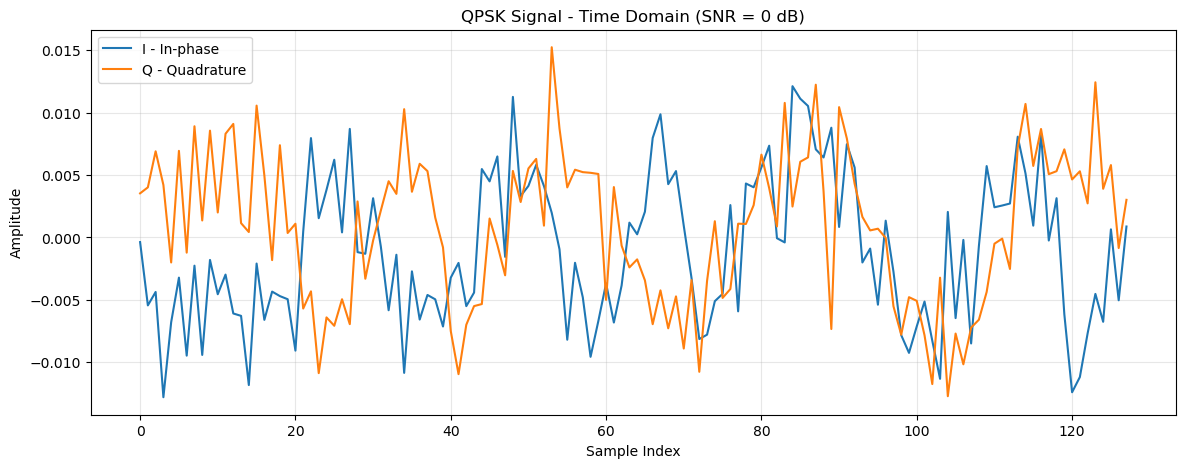

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(n, I, label='I - In-phase')
plt.plot(n, Q, label='Q - Quadrature')

plt.title('QPSK Signal - Time Domain (SNR = 0 dB)')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

- note :
$$
A[n]=\sqrt{I[n]^2+Q[n]^2}
$$

$$
\phi[n]=\operatorname{atan2}(Q[n],I[n])
$$

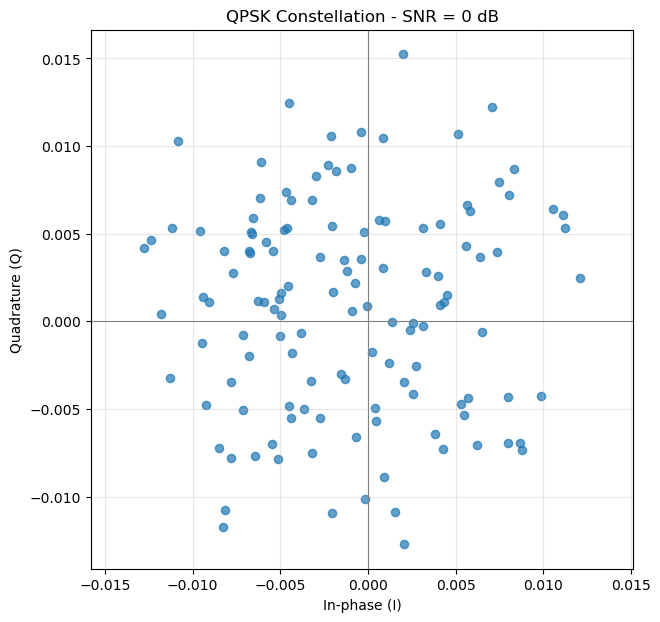

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(I, Q, s=35, alpha=0.7)

plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)

plt.title('QPSK Constellation - SNR = 0 dB')
plt.xlabel('In-phase (I)')
plt.ylabel('Quadrature (Q)')

plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

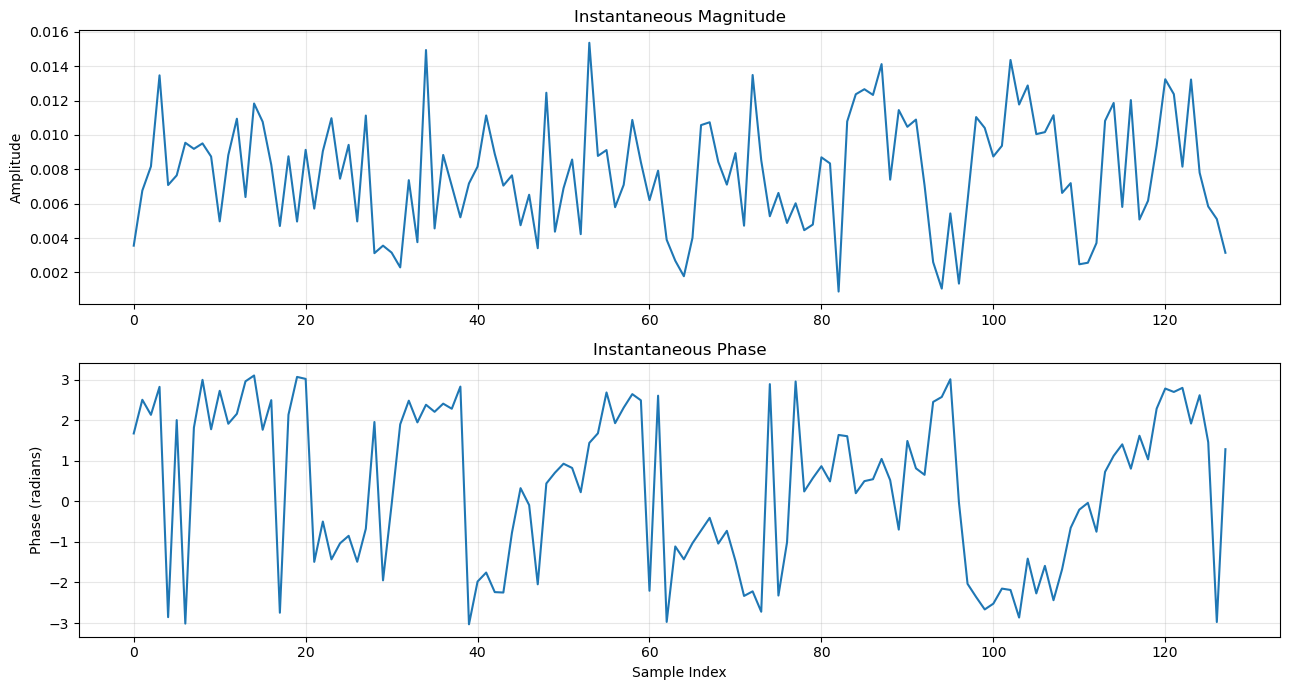

In [ ]:
amplitude = np.sqrt(I**2 + Q**2)
phase = np.arctan2(Q, I)

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].plot(n, amplitude)
axes[0].set_title('Instantaneous Magnitude')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)

axes[1].plot(n, phase)
axes[1].set_title('Instantaneous Phase')
axes[1].set_xlabel('Sample Index')
axes[1].set_ylabel('Phase (radians)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. data intergity and quality checks

## 3. dataset distribution analysis

## 4. modulation specific visualization

## 5. SNR and noise analysis

## 6. statistical signal analysis

## 7. EDA and key findings